
# Insurance Claims & Severity Analytics

## Business Objective

Analyze insurance claim amounts, severity patterns, and financial exposure to identify high-value claims, claim concentration, and differences across policy types and claim outcomes.

### Key Business Questions

- How are claim amounts and severity distributed?
- Which insurance policy types contribute the highest claim amounts?
- How concentrated is claim exposure among high-value claims?
- How do claim amounts differ across claim statuses?
- Which claim segments require closer financial monitoring?

### Analysis Approach

Use Python, Pandas, NumPy, Matplotlib, and Seaborn to investigate claim-level financial patterns and generate business insights.

**Scope:** 18 important business requirements, without unnecessary repetition of previous analyses.


In [1]:

# Step 2 — Import Libraries and Connect to MySQL

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, URL
from getpass import getpass

# MySQL connection
db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("Enter MySQL Password: "),
    host="localhost",
    port=3306,
    database="insurance_claims_analytics"
)

engine = create_engine(db_url)

# Verify database connection
with engine.connect() as connection:
    print("Connected Database:", connection.engine.url.database)

print("Libraries imported and MySQL connection successful.")


Connected Database: insurance_claims_analytics
Libraries imported and MySQL connection successful.


In [2]:

# Step 3 — Load Claims & Severity Analysis Datasets

claims = pd.read_sql("SELECT * FROM claims", engine)

policies = pd.read_sql("SELECT * FROM policies", engine)

payments = pd.read_sql("SELECT * FROM payments", engine)

print(f"Claims: {len(claims):,} rows")
print(f"Policies: {len(policies):,} rows")
print(f"Payments: {len(payments):,} rows")

print("\nClaims & Severity datasets loaded successfully.")


Claims: 25,000 rows
Policies: 15,000 rows
Payments: 15,541 rows

Claims & Severity datasets loaded successfully.


In [3]:

# BR 1 — Claim Severity Distribution

claim_amounts = claims["Claim_Amount"]

severity_summary = pd.DataFrame({
    "Metric": [
        "Total Claims",
        "Total Claimed Amount",
        "Average Claim Amount",
        "Median Claim Amount",
        "Standard Deviation",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "99th Percentile",
        "Maximum Claim Amount"
    ],
    "Value": [
        claim_amounts.count(),
        claim_amounts.sum(),
        claim_amounts.mean(),
        claim_amounts.median(),
        claim_amounts.std(),
        claim_amounts.quantile(0.75),
        claim_amounts.quantile(0.90),
        claim_amounts.quantile(0.95),
        claim_amounts.quantile(0.99),
        claim_amounts.max()
    ]
})

display(severity_summary.round(2))


,Metric,Value
0,Total Claims,2.500000e+04
1,Total Claimed Amount,1.053650e+09
2,Average Claim Amount,4.214598e+04
3,Median Claim Amount,2.997978e+04
4,Standard Deviation,4.162995e+04
5,75th Percentile,5.262672e+04
6,90th Percentile,8.689586e+04
7,95th Percentile,1.186471e+05
8,99th Percentile,2.053638e+05
9,Maximum Claim Amount,9.614248e+05


In [4]:

# BR 2 — High-Value Claim Concentration

sorted_claims = claims["Claim_Amount"].sort_values(
    ascending=False
).reset_index(drop=True)

total_claimed = sorted_claims.sum()

concentration_results = []

for percentage in [1, 5, 10]:
    top_n = int(len(sorted_claims) * percentage / 100)

    top_claimed_amount = sorted_claims.head(top_n).sum()

    concentration_results.append({
        "Top Claims (%)": percentage,
        "Number of Claims": top_n,
        "Claimed Amount": top_claimed_amount,
        "Share of Total Claimed (%)":
            (top_claimed_amount / total_claimed) * 100
    })

claim_concentration = pd.DataFrame(concentration_results)

display(claim_concentration.round(2))


,Top Claims (%),Number of Claims,Claimed Amount,Share of Total Claimed (%)
0,1,250,6.888214e+07,6.54
1,5,1250,2.181326e+08,20.70
2,10,2500,3.434793e+08,32.60


In [5]:

# BR 3 — Claim Severity by Insurance Policy Type

claims_by_type = claims.merge(
    policies[["Policy_ID", "Policy_Type"]],
    on="Policy_ID",
    how="left",
    validate="many_to_one"
)

policy_severity = (
    claims_by_type.groupby("Policy_Type")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reset_index()
)

policy_severity["Claimed_Amount_Share_Pct"] = (
    policy_severity["Total_Claimed_Amount"]
    / policy_severity["Total_Claimed_Amount"].sum()
    * 100
)

policy_severity = policy_severity.sort_values(
    "Total_Claimed_Amount", ascending=False
)

display(policy_severity.round(2))


,Policy_Type,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity,Claimed_Amount_Share_Pct
0,Auto,9832,4.174665e+08,42459.97,30304.48,39.62
1,Health,7784,3.301273e+08,42411.00,30215.80,31.33
2,Home,4458,1.871221e+08,41974.46,30012.06,17.76
3,Life,2926,1.189337e+08,40647.21,28195.46,11.29


In [6]:

# BR 4 — Claim Severity by Claim Status

status_severity = (
    claims.groupby("Claim_Status")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reset_index()
)

status_severity["Claimed_Amount_Share_Pct"] = (
    status_severity["Total_Claimed_Amount"]
    / status_severity["Total_Claimed_Amount"].sum()
    * 100
)

status_severity = status_severity.sort_values(
    "Total_Claimed_Amount",
    ascending=False
)

display(status_severity.round(2))


,Claim_Status,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity,Claimed_Amount_Share_Pct
3,Settled,10569,4.477088e+08,42360.56,30006.22,42.49
0,Approved,6100,2.524593e+08,41386.77,29456.39,23.96
2,Rejected,4256,1.820868e+08,42783.55,30392.21,17.28
1,Pending,4075,1.713947e+08,42060.06,30320.92,16.27


In [7]:

# BR 5 — Annual Claim Severity Trends

claims["Claim_Date"] = pd.to_datetime(claims["Claim_Date"])

annual_severity = (
    claims.assign(Claim_Year=claims["Claim_Date"].dt.year)
    .groupby("Claim_Year")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reset_index()
    .sort_values("Claim_Year")
)

annual_severity["YoY_Avg_Severity_Change_Pct"] = (
    annual_severity["Average_Claim_Severity"]
    .pct_change() * 100
)

display(annual_severity.round(2))


,Claim_Year,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity,YoY_Avg_Severity_Change_Pct
0,2020,1639,6.694709e+07,40846.30,29638.70,NaN
1,2021,3723,1.568411e+08,42127.61,30700.30,3.14
2,2022,4099,1.722129e+08,42013.40,29857.67,-0.27
3,2023,4163,1.748928e+08,42011.23,30161.37,-0.01
4,2024,4376,1.850646e+08,42290.82,29612.18,0.67
5,2025,4316,1.829774e+08,42395.12,29980.91,0.25
6,2026,2684,1.147138e+08,42739.85,29516.94,0.81


In [8]:

# BR 6 — Claim Amount Distribution by Severity Bands

severity_labels = ["Low", "Medium", "High", "Very High"]

claims["Severity_Band"] = pd.cut(
    claims["Claim_Amount"],
    bins=[-np.inf, 25000, 50000, 100000, np.inf],
    labels=severity_labels
)

severity_bands = (
    claims.groupby("Severity_Band", observed=True)
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Amount=("Claim_Amount", "mean")
    )
    .reindex(severity_labels)
    .reset_index()
)

severity_bands["Claim_Share_Pct"] = (
    severity_bands["Total_Claims"]
    / severity_bands["Total_Claims"].sum() * 100
)

severity_bands["Claimed_Amount_Share_Pct"] = (
    severity_bands["Total_Claimed_Amount"]
    / severity_bands["Total_Claimed_Amount"].sum() * 100
)

display(severity_bands.round(2))


,Severity_Band,Total_Claims,Total_Claimed_Amount,Average_Claim_Amount,Claim_Share_Pct,Claimed_Amount_Share_Pct
0,Low,10358,1.539291e+08,14860.89,41.43,14.61
1,Medium,7923,2.825845e+08,35666.35,31.69,26.82
2,High,4858,3.330417e+08,68555.31,19.43,31.61
3,Very High,1861,2.840942e+08,152656.75,7.44,26.96


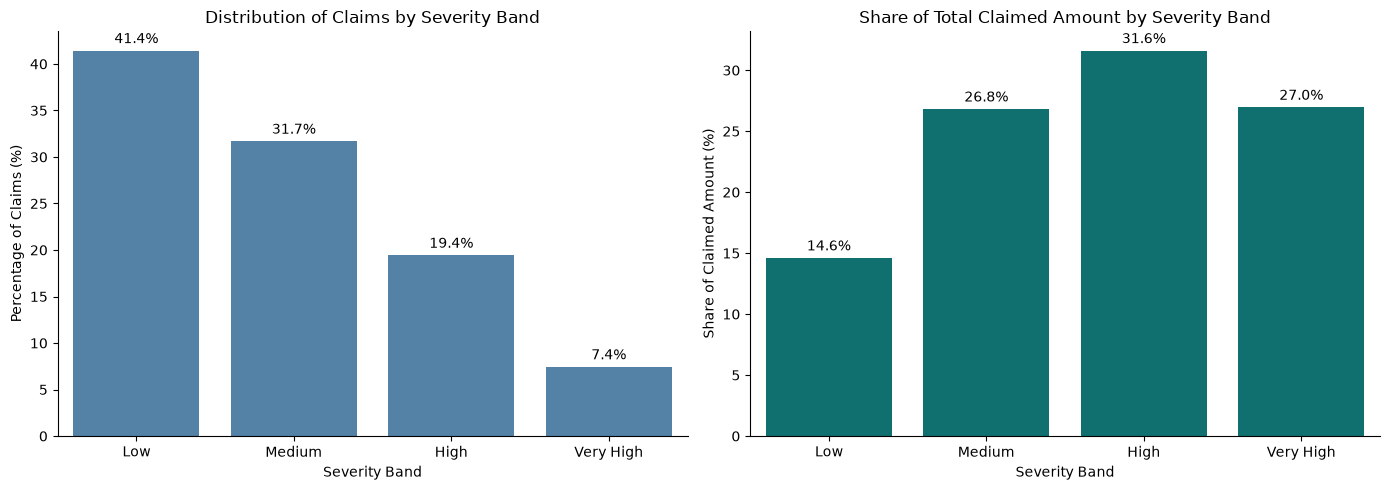

In [9]:

# BR 6 — Claim Severity Distribution Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=severity_bands,
    x="Severity_Band",
    y="Claim_Share_Pct",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Claims by Severity Band")
axes[0].set_xlabel("Severity Band")
axes[0].set_ylabel("Percentage of Claims (%)")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3)

sns.barplot(
    data=severity_bands,
    x="Severity_Band",
    y="Claimed_Amount_Share_Pct",
    color="teal",
    ax=axes[1]
)

axes[1].set_title("Share of Total Claimed Amount by Severity Band")
axes[1].set_xlabel("Severity Band")
axes[1].set_ylabel("Share of Claimed Amount (%)")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3)

sns.despine()
plt.tight_layout()
plt.show()


In [10]:

# BR 7 — High-Value Claims by Policy Type

high_value_by_policy = (
    claims_by_type.assign(
        Is_High_Value=claims_by_type["Claim_Amount"] > 100000
    )
    .groupby("Policy_Type")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        High_Value_Claims=("Is_High_Value", "sum"),
        High_Value_Claimed_Amount=(
            "Claim_Amount",
            lambda x: x[x > 100000].sum()
        )
    )
    .reset_index()
)

high_value_by_policy["High_Value_Claim_Rate_Pct"] = (
    high_value_by_policy["High_Value_Claims"]
    / high_value_by_policy["Total_Claims"] * 100
)

high_value_by_policy = high_value_by_policy.sort_values(
    "High_Value_Claim_Rate_Pct",
    ascending=False
)

display(high_value_by_policy.round(2))


,Policy_Type,Total_Claims,High_Value_Claims,High_Value_Claimed_Amount,High_Value_Claim_Rate_Pct
2,Home,4458,355,5.166638e+07,7.96
0,Auto,9832,744,1.134365e+08,7.57
1,Health,7784,563,8.756902e+07,7.23
3,Life,2926,199,3.142227e+07,6.80


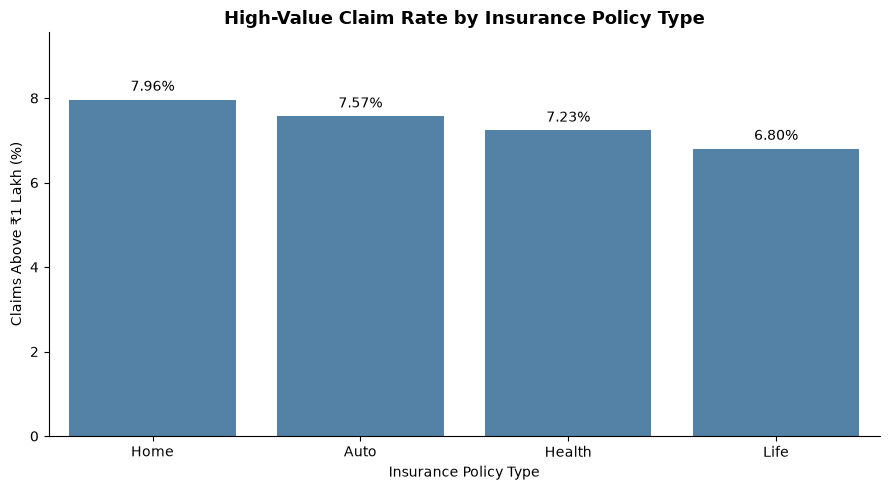

In [11]:

# BR 7 — High-Value Claim Rate by Policy Type

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=high_value_by_policy,
    x="Policy_Type",
    y="High_Value_Claim_Rate_Pct",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title(
    "High-Value Claim Rate by Insurance Policy Type",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Insurance Policy Type")
plt.ylabel("Claims Above ₹1 Lakh (%)")
plt.ylim(0, high_value_by_policy["High_Value_Claim_Rate_Pct"].max() * 1.2)

sns.despine()
plt.tight_layout()
plt.show()


In [12]:

# BR 8 — Claim Amount vs Policy Coverage

coverage_analysis = claims.merge(
    policies[["Policy_ID", "Coverage_Amount"]],
    on="Policy_ID",
    how="left",
    validate="many_to_one"
)

coverage_analysis["Exceeds_Coverage"] = (
    coverage_analysis["Claim_Amount"]
    > coverage_analysis["Coverage_Amount"]
)

coverage_analysis["Excess_Amount"] = (
    coverage_analysis["Claim_Amount"]
    - coverage_analysis["Coverage_Amount"]
).clip(lower=0)

coverage_summary = pd.DataFrame({
    "Metric": [
        "Total Claims",
        "Claims Exceeding Coverage",
        "Coverage Exceedance Rate (%)",
        "Total Claimed Amount Above Coverage",
        "Maximum Excess Amount"
    ],
    "Value": [
        len(coverage_analysis),
        coverage_analysis["Exceeds_Coverage"].sum(),
        coverage_analysis["Exceeds_Coverage"].mean() * 100,
        coverage_analysis["Excess_Amount"].sum(),
        coverage_analysis["Excess_Amount"].max()
    ]
})

display(coverage_summary.round(2))


,Metric,Value
0,Total Claims,25000.00
1,Claims Exceeding Coverage,143.00
2,Coverage Exceedance Rate (%),0.57
3,Total Claimed Amount Above Coverage,4265992.47
4,Maximum Excess Amount,117249.86


In [13]:

# BR 9 — Claim-to-Coverage Ratio Analysis

valid_coverage = coverage_analysis[
    coverage_analysis["Coverage_Amount"] > 0
].copy()

valid_coverage["Claim_to_Coverage_Pct"] = (
    valid_coverage["Claim_Amount"]
    / valid_coverage["Coverage_Amount"] * 100
)

coverage_utilization_summary = pd.DataFrame({
    "Metric": [
        "Claims with Valid Coverage",
        "Average Claim-to-Coverage Ratio (%)",
        "Median Claim-to-Coverage Ratio (%)",
        "90th Percentile (%)",
        "95th Percentile (%)",
        "Claims Using Over 50% of Coverage",
        "Claims Using Over 80% of Coverage"
    ],
    "Value": [
        len(valid_coverage),
        valid_coverage["Claim_to_Coverage_Pct"].mean(),
        valid_coverage["Claim_to_Coverage_Pct"].median(),
        valid_coverage["Claim_to_Coverage_Pct"].quantile(0.90),
        valid_coverage["Claim_to_Coverage_Pct"].quantile(0.95),
        (valid_coverage["Claim_to_Coverage_Pct"] > 50).sum(),
        (valid_coverage["Claim_to_Coverage_Pct"] > 80).sum()
    ]
})

display(coverage_utilization_summary.round(2))


,Metric,Value
0,Claims with Valid Coverage,25000.00
1,Average Claim-to-Coverage Ratio (%),10.27
2,Median Claim-to-Coverage Ratio (%),5.46
3,90th Percentile (%),23.44
4,95th Percentile (%),35.56
5,Claims Using Over 50% of Coverage,649.00
6,Claims Using Over 80% of Coverage,239.00


In [14]:

# BR 10 — Claim Severity by Policy Coverage Band

coverage_labels = [
    "Up to 2 Lakh",
    "2–5 Lakh",
    "5–10 Lakh",
    "Above 10 Lakh"
]

coverage_analysis["Coverage_Band"] = pd.cut(
    coverage_analysis["Coverage_Amount"],
    bins=[0, 200000, 500000, 1000000, np.inf],
    labels=coverage_labels
)

coverage_band_severity = (
    coverage_analysis.groupby("Coverage_Band", observed=True)
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reindex(coverage_labels)
    .reset_index()
)

coverage_band_severity["Claimed_Amount_Share_Pct"] = (
    coverage_band_severity["Total_Claimed_Amount"]
    / coverage_band_severity["Total_Claimed_Amount"].sum()
    * 100
)

display(coverage_band_severity.round(2))


,Coverage_Band,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity,Claimed_Amount_Share_Pct
0,Up to 2 Lakh,2480,1.026419e+08,41387.88,29250.06,9.74
1,2–5 Lakh,8841,3.710257e+08,41966.48,29712.36,35.21
2,5–10 Lakh,8099,3.442287e+08,42502.62,30730.41,32.67
3,Above 10 Lakh,5580,2.357533e+08,42249.69,29719.47,22.37


In [15]:

# BR 11 — High-Value Claim Rate by Coverage Band

high_value_coverage = (
    coverage_analysis.assign(
        Is_High_Value=coverage_analysis["Claim_Amount"] > 100000
    )
    .groupby("Coverage_Band", observed=True)
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        High_Value_Claims=("Is_High_Value", "sum")
    )
    .reindex(coverage_labels)
    .reset_index()
)

high_value_coverage["High_Value_Claim_Rate_Pct"] = (
    high_value_coverage["High_Value_Claims"]
    / high_value_coverage["Total_Claims"] * 100
)

display(high_value_coverage.round(2))


,Coverage_Band,Total_Claims,High_Value_Claims,High_Value_Claim_Rate_Pct
0,Up to 2 Lakh,2480,192,7.74
1,2–5 Lakh,8841,647,7.32
2,5–10 Lakh,8099,614,7.58
3,Above 10 Lakh,5580,408,7.31


In [16]:

# BR 12 — Inspect Available Claim Fields

print("Available Claims Columns:")
print(claims.columns.tolist())


Available Claims Columns:
['Claim_ID', 'Policy_ID', 'Claim_Date', 'Claim_Amount', 'Claim_Status', 'Fraud_Flag', 'Claim_Type', 'Severity_Band']


In [17]:

# BR 12 — Claim Severity by Claim Type

claim_type_severity = (
    claims.groupby("Claim_Type")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reset_index()
)

claim_type_severity["Claimed_Amount_Share_Pct"] = (
    claim_type_severity["Total_Claimed_Amount"]
    / claim_type_severity["Total_Claimed_Amount"].sum()
    * 100
)

claim_type_severity = claim_type_severity.sort_values(
    "Total_Claimed_Amount",
    ascending=False
)

display(claim_type_severity.round(2))


,Claim_Type,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity,Claimed_Amount_Share_Pct
0,Auto,9832,4.174665e+08,42459.97,30304.48,39.62
1,Health,7784,3.301273e+08,42411.00,30215.80,31.33
2,Home,4458,1.871221e+08,41974.46,30012.06,17.76
3,Life,2926,1.189337e+08,40647.21,28195.46,11.29


In [18]:

# BR 12 — Claim Severity by Fraud Flag

fraud_severity = (
    claims.groupby("Fraud_Flag")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reset_index()
)

fraud_severity["Claimed_Amount_Share_Pct"] = (
    fraud_severity["Total_Claimed_Amount"]
    / fraud_severity["Total_Claimed_Amount"].sum() * 100
)

display(fraud_severity.round(2))


,Fraud_Flag,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity,Claimed_Amount_Share_Pct
0,0,24079,1.014971e+09,42151.73,30010.04,96.33
1,1,921,3.867815e+07,41995.82,28865.29,3.67


In [19]:

# BR 13 — High-Value Claim Concentration by Claim Status

status_high_value = (
    claims.assign(
        Is_High_Value=claims["Claim_Amount"] > 100000
    )
    .groupby("Claim_Status")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        High_Value_Claims=("Is_High_Value", "sum"),
        High_Value_Claimed_Amount=(
            "Claim_Amount",
            lambda x: x[x > 100000].sum()
        )
    )
    .reset_index()
)

status_high_value["High_Value_Claim_Rate_Pct"] = (
    status_high_value["High_Value_Claims"]
    / status_high_value["Total_Claims"] * 100
)

status_high_value = status_high_value.sort_values(
    "High_Value_Claim_Rate_Pct",
    ascending=False
)

display(status_high_value.round(2))


,Claim_Status,Total_Claims,High_Value_Claims,High_Value_Claimed_Amount,High_Value_Claim_Rate_Pct
3,Settled,10569,802,1.236156e+08,7.59
1,Pending,4075,307,4.575243e+07,7.53
0,Approved,6100,443,6.582549e+07,7.26
2,Rejected,4256,309,4.890071e+07,7.26


In [20]:

# BR 14 — Claim Severity Outlier Analysis (IQR Method)

q1 = claims["Claim_Amount"].quantile(0.25)
q3 = claims["Claim_Amount"].quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

severity_outliers = claims[
    claims["Claim_Amount"] > upper_bound
].copy()

outlier_summary = pd.DataFrame({
    "Metric": [
        "Q1 (25th Percentile)",
        "Q3 (75th Percentile)",
        "IQR",
        "Upper Outlier Threshold",
        "Total Severity Outliers",
        "Outlier Rate (%)",
        "Total Outlier Claimed Amount",
        "Outlier Share of Total Claimed (%)"
    ],
    "Value": [
        q1,
        q3,
        iqr,
        upper_bound,
        len(severity_outliers),
        len(severity_outliers) / len(claims) * 100,
        severity_outliers["Claim_Amount"].sum(),
        severity_outliers["Claim_Amount"].sum()
        / claims["Claim_Amount"].sum() * 100
    ]
})

display(outlier_summary.round(2))


,Metric,Value
0,Q1 (25th Percentile),1.686371e+04
1,Q3 (75th Percentile),5.262672e+04
2,IQR,3.576300e+04
3,Upper Outlier Threshold,1.062712e+05
4,Total Severity Outliers,1.583000e+03
5,Outlier Rate (%),6.330000e+00
6,Total Outlier Claimed Amount,2.554197e+08
7,Outlier Share of Total Claimed (%),2.424000e+01


In [21]:

# BR 15 — Quarterly Claim Severity Analysis

quarterly_claims = claims[
    claims["Claim_Date"].dt.year.between(2021, 2025)
].copy()

quarterly_claims["Quarter"] = (
    "Q" + quarterly_claims["Claim_Date"].dt.quarter.astype(str)
)

quarterly_severity = (
    quarterly_claims.groupby("Quarter")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Severity=("Claim_Amount", "mean"),
        Median_Claim_Severity=("Claim_Amount", "median")
    )
    .reindex(["Q1", "Q2", "Q3", "Q4"])
    .reset_index()
)

display(quarterly_severity.round(2))


,Quarter,Total_Claims,Total_Claimed_Amount,Average_Claim_Severity,Median_Claim_Severity
0,Q1,5078,2.132514e+08,41995.16,29535.66
1,Q2,5056,2.133491e+08,42197.22,30222.46
2,Q3,5197,2.203440e+08,42398.31,30613.34
3,Q4,5346,2.250442e+08,42095.81,30038.07


In [22]:

# BR 16 — Annual Claim Severity Volatility

annual_volatility = (
    claims.assign(
        Claim_Year=claims["Claim_Date"].dt.year
    )
    .groupby("Claim_Year")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Average_Severity=("Claim_Amount", "mean"),
        Severity_Std_Dev=("Claim_Amount", "std")
    )
    .reset_index()
)

annual_volatility["Coefficient_of_Variation_Pct"] = (
    annual_volatility["Severity_Std_Dev"]
    / annual_volatility["Average_Severity"] * 100
)

display(annual_volatility.round(2))


,Claim_Year,Total_Claims,Average_Severity,Severity_Std_Dev,Coefficient_of_Variation_Pct
0,2020,1639,40846.30,40298.31,98.66
1,2021,3723,42127.61,39513.21,93.79
2,2022,4099,42013.40,39850.88,94.85
3,2023,4163,42011.23,41378.58,98.49
4,2024,4376,42290.82,40885.58,96.68
5,2025,4316,42395.12,42766.50,100.88
6,2026,2684,42739.85,47327.63,110.73


In [23]:

# BR 17 — Pending and Approved Claim Exposure

open_claims = claims[
    claims["Claim_Status"].isin(["Pending", "Approved"])
].copy()

open_claim_exposure = (
    open_claims.groupby("Claim_Status")
    .agg(
        Total_Claims=("Claim_Amount", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum"),
        Average_Claim_Amount=("Claim_Amount", "mean")
    )
    .reset_index()
)

open_claim_exposure["Share_of_Total_Claimed_Pct"] = (
    open_claim_exposure["Total_Claimed_Amount"]
    / claims["Claim_Amount"].sum() * 100
)

display(open_claim_exposure.round(2))

print(f"Combined Claims: {len(open_claims):,}")
print(
    f"Combined Claimed Amount: "
    f"₹{open_claims['Claim_Amount'].sum():,.2f}"
)


,Claim_Status,Total_Claims,Total_Claimed_Amount,Average_Claim_Amount,Share_of_Total_Claimed_Pct
0,Approved,6100,2.524593e+08,41386.77,23.96
1,Pending,4075,1.713947e+08,42060.06,16.27


Combined Claims: 10,175
Combined Claimed Amount: ₹423,854,033.49


In [24]:

# BR 18 — Claim Severity Concentration by Policy

policy_claim_exposure = (
    claims.groupby("Policy_ID")
    .agg(
        Total_Claims=("Claim_ID", "count"),
        Total_Claimed_Amount=("Claim_Amount", "sum")
    )
    .reset_index()
    .sort_values("Total_Claimed_Amount", ascending=False)
)

total_claimed = policy_claim_exposure[
    "Total_Claimed_Amount"
].sum()

top_10_count = int(
    np.ceil(len(policy_claim_exposure) * 0.10)
)

top_10_policies = policy_claim_exposure.head(top_10_count)

policy_concentration = pd.DataFrame({
    "Metric": [
        "Policies With Claims",
        "Top 10% Policy Count",
        "Total Claimed Amount",
        "Top 10% Policy Claimed Amount",
        "Top 10% Claimed Amount Share (%)",
        "Maximum Claims per Policy",
        "Maximum Claimed Amount per Policy"
    ],
    "Value": [
        len(policy_claim_exposure),
        top_10_count,
        total_claimed,
        top_10_policies["Total_Claimed_Amount"].sum(),
        top_10_policies["Total_Claimed_Amount"].sum()
        / total_claimed * 100,
        policy_claim_exposure["Total_Claims"].max(),
        policy_claim_exposure["Total_Claimed_Amount"].max()
    ]
})

display(policy_concentration.round(2))


,Metric,Value
0,Policies With Claims,1.218000e+04
1,Top 10% Policy Count,1.218000e+03
2,Total Claimed Amount,1.053650e+09
3,Top 10% Policy Claimed Amount,3.121229e+08
4,Top 10% Claimed Amount Share (%),2.962000e+01
5,Maximum Claims per Policy,9.000000e+00
6,Maximum Claimed Amount per Policy,1.049471e+06


## Key Business Findings — Claims Severity Analytics

1. **Overall Claim Exposure:** The portfolio contains 25,000 claims with approximately ₹105.36 crore in total claimed amounts. Average claim severity is ₹42,145.98, while median severity is ₹29,979.78, indicating a right-skewed distribution.

2. **High-Value Claim Concentration:** Claims exceeding ₹1 lakh represent 7.44% of claim volume but account for 26.96% of total claimed amounts.

3. **Severity Outliers:** The IQR method identified 1,583 unusually high-value claims (6.33%), representing 24.24% of total claimed amounts.

4. **Policy Coverage Exposure:** A total of 143 claims (0.57%) exceed their associated policy coverage amounts, with approximately ₹42.66 lakh in aggregate excess claimed value.

5. **Claim Status Exposure:** Pending and Approved claims collectively represent 10,175 claims and approximately ₹42.39 crore in requested claim amounts. These values are not confirmed unpaid liabilities.

6. **Fraud-Flagged Claim Severity:** Fraud-flagged claims account for 3.67% of total claimed amounts. Their average severity is slightly lower than that of non-flagged claims, indicating no notable severity difference in this descriptive comparison.

7. **Annual and Seasonal Patterns:** Average claim severity remains relatively stable across calendar quarters. However, severity variability is higher in the partial 2026 data, with a coefficient of variation of 110.73%.

8. **Policy-Level Concentration:** The top 10% of claim-bearing policies contribute 29.62% of total claimed amounts, indicating concentrated financial exposure.

### Business Recommendations

- Prioritize financial monitoring of high-value claims and statistical severity outliers.
- Review claims exceeding policy coverage to determine whether they require adjustment or additional investigation.
- Monitor Pending and Approved claims separately to support operational planning without treating requested amounts as confirmed liabilities.
- Investigate unusually concentrated policy-level claim exposure using policy history and relevant business context.
- Track severity distributions and volatility over time to identify emerging changes in claim exposure.

**Conclusion:** Claim severity is relatively stable on average, but high-value claims, upper-tail outliers, and concentrated policy-level exposure account for a disproportionate share of total claimed amounts. These findings support more targeted claims monitoring and financial risk assessment.